### Backpropagation

Ein neuronales Netz lernt, indem es seine Gewichte und Biaswerte schrittweise so verändert, dass der Fehler kleiner
wird. Dafür muss es für jeden Parameter wissen: Wird der Fehler größer oder kleiner, wenn ich diesen Parameter ein
wenig vergrößere, und wie stark? Die Antwort gibt die **Ableitung des Fehlers nach dem Parameter**.

**Backpropagation** berechnet alle diese Ableitungen mit einem einzigen Durchgang rückwärts durch das Netz. Wir
gehen in Stufen vor:

1. Rechengraph und Kettenregel
2. ein Neuron mit einem Input
3. ein Neuron mit zwei Inputs
4. zwei Neuronen hintereinander
5. ein Netz mit zwei versteckten Neuronen
6. ein Netz mit zwei Ausgaben

Vorher wiederholen wir kurz, was wir aus den Notebooks Perzeptron und Neuron und Gradientenabstieg brauchen.
Alle Beispiele kann man mit dem Taschenrechner nachrechnen. Der Code rechnet sie zur Kontrolle nach. Danach prüfen
wir die Ableitungen auf einem zweiten Weg, lassen ein Netz die XOR-Funktion lernen und bauen eine kleine Klasse, die
Backpropagation für beliebige Rechnungen automatisch ausführt.

#### Wiederholung: Neuron und Aktivierung

Ein **Neuron** berechnet aus seinen Inputs eine gewichtete Summe und schickt sie durch eine **Aktivierungsfunktion**
$f$:

$$z = w_1 x_1 + w_2 x_2 + b, \qquad a = f(z)$$

Wir benutzen zwei Aktivierungsfunktionen:

- **Sigmoid** $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ liefert Werte zwischen 0 und 1. Im Ausgabeneuron lesen wir den
  Wert als Wahrscheinlichkeit für die Klasse 1. Den Ausgabewert des Netzes nennen wir $\hat{y}$.
- **ReLU** $(z) = \max(0, z)$ lässt positive Werte durch und macht aus negativen eine 0. Sie wird in den
  versteckten Schichten benutzt.

In [1]:
import math

def sigmoid(z):
    return 1 / (1 + math.exp(-z))

def relu(z):
    return max(0, z)

print(sigmoid(0), sigmoid(1), sigmoid(-1))
print(relu(2), relu(-1))

0.5 0.7310585786300049 0.2689414213699951
2 0


#### Wiederholung: Fehler

Den Fehler messen wir mit der **Binary Cross-Entropy** (hergeleitet im Notebook Gradientenabstieg). $\hat{y}$ ist die
Wahrscheinlichkeit, die das Netz der Klasse 1 gibt, $y$ die richtige Klasse. Der Fehler ist der negative Logarithmus
der Wahrscheinlichkeit, die das Netz der **richtigen** Klasse gibt:

$$L = -\big(y \ln(\hat{y}) + (1 - y)\ln(1 - \hat{y})\big)$$

Für $y = 1$ bleibt $-\ln(\hat{y})$ übrig, für $y = 0$ bleibt $-\ln(1 - \hat{y})$. Sind es mehrere Beispiele, nimmt man
den Mittelwert.

In [2]:
def bce(yh, y):
    return -(y * math.log(yh) + (1 - y) * math.log(1 - yh))

print('yh      y=1     y=0')
for yh in [0.99, 0.9, 0.5, 0.1, 0.01]:
    print(yh, '  ', round(bce(yh, 1), 4), '  ', round(bce(yh, 0), 4))

yh      y=1     y=0
0.99    0.0101    4.6052
0.9    0.1054    2.3026
0.5    0.6931    0.6931
0.1    2.3026    0.1054
0.01    4.6052    0.0101


Gibt das Netz der richtigen Klasse die Wahrscheinlichkeit 0.99, ist der Fehler fast 0. Bei 0.5 (das Netz rät) ist er
$\ln 2 \approx 0.6931$. Je sicherer sich das Netz bei einer falschen Antwort ist, desto größer wird der Fehler. In
Stufe 1 sehen wir einen weiteren Vorteil: Zusammen mit der Sigmoidfunktion wird die Ableitung sehr einfach.

#### Gradientenabstieg

Jeder Parameter $p$ wird ein Stück gegen seine Ableitung verschoben:

$$p_{neu} = p - lr \cdot \frac{\partial L}{\partial p}$$

Ist die Ableitung positiv, wächst der Fehler mit $p$, also wird $p$ kleiner. Ist sie negativ, wird $p$ größer. Die
**Lernrate** $lr$ legt fest, wie groß der Schritt ist. (Hier ist $p$ ein beliebiger Parameter, keine
Wahrscheinlichkeit.)

### Rechengraph und Kettenregel

Eine Rechnung zerlegen wir in einfache Schritte und zeichnen sie als **Rechengraph**. Beispiel:
$f = (x + y) \cdot z$ mit $x = 1$, $y = 2$, $z = -2$. Wir rechnen in zwei Schritten: $q = x + y$, dann
$f = q \cdot z$.

<img src="graph_plusmal.png" width="600">

Schwarz stehen die Werte, die vorwärts berechnet werden: $q = 3$, $f = -6$. Rot stehen die Ableitungen von $f$ nach
dem jeweiligen Wert. Sie werden rückwärts berechnet, von rechts nach links:

- Ganz rechts: $\frac{\partial f}{\partial f} = 1$.
- Am Mal-Knoten $f = q \cdot z$: $\frac{\partial f}{\partial q} = z = -2$ und $\frac{\partial f}{\partial z} = q = 3$.
- Am Plus-Knoten $q = x + y$: Die **lokalen Ableitungen** sind $\frac{\partial q}{\partial x} = 1$ und
  $\frac{\partial q}{\partial y} = 1$. Nach der **Kettenregel** gilt
  $\frac{\partial f}{\partial x} = \frac{\partial f}{\partial q} \cdot \frac{\partial q}{\partial x} = -2 \cdot 1 = -2$,
  ebenso $\frac{\partial f}{\partial y} = -2$.

Rückwärts multipliziert man also die Ableitung, die von rechts ankommt, mit der lokalen Ableitung des Knotens.
Daraus folgen zwei Faustregeln:

- Ein **Plus-Knoten** gibt die ankommende Ableitung unverändert an alle Summanden weiter.
- Ein **Mal-Knoten** multipliziert die ankommende Ableitung mit dem jeweils anderen Faktor.

Ob das stimmt, prüfen wir, indem wir $x$ ein klein wenig vergrößern und schauen, wie stark sich $f$ ändert:

In [3]:
def f(x, y, z):
    return (x + y) * z

eps = 0.0001
print(f(1, 2, -2))
print((f(1 + eps, 2, -2) - f(1, 2, -2)) / eps)
print((f(1, 2, -2 + eps) - f(1, 2, -2)) / eps)

-6
-1.9999999999953388
3.00000000000189


Wird $x$ um 0.0001 größer, ändert sich $f$ um das $-2$-Fache davon, bei $z$ um das 3-Fache. Das sind genau die roten
Werte. (Die letzten Stellen weichen wegen der Rundung im Rechner ein wenig ab.)

#### Mehrere Wege

Bei $f = (x + y) \cdot x$ kommt $x$ auf zwei Wegen zum Ergebnis: über $q = x + y$ und direkt als Faktor. Mit
$x = 3$, $y = -1$:

<img src="graph_zweiwege.png" width="600">

Über $q$ kommt der Beitrag $3 \cdot 1 = 3$, direkt der Beitrag $q = 2$. **Führen mehrere Wege von einer Variablen
zum Ergebnis, dann werden die Beiträge addiert:** $\frac{\partial f}{\partial x} = 3 + 2 = 5$. Zur Kontrolle:
$f = x^2 + xy$ hat die Ableitung $2x + y = 5$.

In [4]:
def f2(x, y):
    return (x + y) * x

print((f2(3 + eps, -1) - f2(3, -1)) / eps)

5.000100000014385


### Stufe 1: Ein Neuron mit einem Input

Ein Neuron mit Sigmoid und dem Fehler $L$ als Rechengraph, mit $x = 2$, $w = 0.5$, $b = -1$ und der richtigen
Klasse $y = 1$:

<img src="neuron1.png" width="750">

Die lokalen Ableitungen:

- $\frac{\partial z}{\partial w} = x$ und $\frac{\partial z}{\partial b} = 1$
- $\frac{\partial \hat{y}}{\partial z} = \hat{y}(1 - \hat{y})$, das ist die Ableitung der Sigmoidfunktion
  (Herleitung in den Aufgaben)
- $\frac{\partial L}{\partial \hat{y}} = -\frac{y}{\hat{y}} + \frac{1 - y}{1 - \hat{y}}$

Multipliziert man die beiden letzten, wird es überraschend einfach. Für $y = 1$:
$-\frac{1}{\hat{y}} \cdot \hat{y}(1 - \hat{y}) = -(1 - \hat{y}) = \hat{y} - 1$. Für $y = 0$:
$\frac{1}{1 - \hat{y}} \cdot \hat{y}(1 - \hat{y}) = \hat{y}$. In beiden Fällen ist

$$\delta = \frac{\partial L}{\partial z} = \hat{y} - y$$

Diese Ableitung nach der Summe $z$ eines Neurons nennen wir $\delta$ (delta), das **Fehlersignal** des Neurons. Dass
sie so einfach ist, ist der Grund, warum man Sigmoid und Binary Cross-Entropy zusammen benutzt. Mit der Kettenregel
folgt:

$$\frac{\partial L}{\partial w} = \delta \cdot x, \qquad \frac{\partial L}{\partial b} = \delta$$

Im Beispiel: $z = 0$, $\hat{y} = 0.5$, $L = 0.6931$, $\delta = -0.5$, also $\frac{\partial L}{\partial w} = -1$
und $\frac{\partial L}{\partial b} = -0.5$. Mit der Lernrate $lr = 0.5$:

$$w_{neu} = 0.5 - 0.5 \cdot (-1) = 1, \qquad b_{neu} = -1 - 0.5 \cdot (-0.5) = -0.75$$

Mit den neuen Werten ist $z = 1.25$, $\hat{y} = 0.7773$ und $L = 0.2519$. Der Fehler ist kleiner geworden.

In [5]:
x, y = 2, 1
w, b = 0.5, -1
lr = 0.5

z = w * x + b
yh = sigmoid(z)
delta = yh - y
print('vorwärts:', z, yh, round(bce(yh, y), 4))
print('rückwärts:', delta, delta * x, delta)

w = w - lr * delta * x
b = b - lr * delta
z = w * x + b
print('neu:', w, b, z, round(sigmoid(z), 4), round(bce(sigmoid(z), y), 4))

vorwärts: 0.0 0.5 0.6931
rückwärts: -0.5 -1.0 -0.5
neu: 1.0 -0.75 1.25 0.7773 0.2519


**Warum nicht der quadratische Fehler?** Früher hat man oft den quadratischen Fehler $L = \frac{1}{2}(y - \hat{y})^2$
benutzt. Dann ist $\frac{\partial L}{\partial \hat{y}} = \hat{y} - y$, und mit der Ableitung der Sigmoidfunktion wird
das Fehlersignal

$$\delta = (\hat{y} - y) \cdot \hat{y}(1 - \hat{y})$$

Der zusätzliche Faktor $\hat{y}(1 - \hat{y})$ ist fast 0, wenn $\hat{y}$ nahe bei 0 oder 1 liegt. Gerade wenn das
Netz sicher und falsch ist, z.B. $\hat{y} = 0.01$ bei $y = 1$, lernt es dann kaum etwas:

In [6]:
yh, y = 0.01, 1
print('Binary Cross-Entropy:', round(yh - y, 4))
print('quadratischer Fehler:', round((yh - y) * yh * (1 - yh), 4))

Binary Cross-Entropy: -0.99
quadratischer Fehler: -0.0098


Mit Binary Cross-Entropy ist das Fehlersignal genau dann groß, wenn das Netz weit danebenliegt.

### Stufe 2: Ein Neuron mit zwei Inputs

Mit zwei Inputs ist $z = w_1 x_1 + w_2 x_2 + b$, und an $\delta$ ändert sich nichts. Für jedes Gewicht gilt
$\frac{\partial L}{\partial w_i} = \delta \cdot x_i$.

> **Merksatz:** Die Ableitung nach einem Gewicht ist das $\delta$ des Neurons, in das das Gewicht führt, mal dem
> Wert, der über dieses Gewicht hereinkommt.

Beispiel mit $x = (-1, 2)$, $w_1 = -1$, $w_2 = 2$, $b = -4$, $y = 1$ und $lr = 0.2$:

| | Rechnung | Wert |
|---|---|---|
| $z$ | $-1 \cdot (-1) + 2 \cdot 2 + (-4)$ | $1$ |
| $\hat{y}$ | $\sigma(1)$ | $0.7311$ |
| $L$ | $-\ln(0.7311)$ | $0.3133$ |
| $\delta$ | $0.7311 - 1$ | $-0.2689$ |
| $\partial L / \partial w_1$ | $\delta \cdot (-1)$ | $0.2689$ |
| $\partial L / \partial w_2$ | $\delta \cdot 2$ | $-0.5379$ |
| $\partial L / \partial b$ | $\delta$ | $-0.2689$ |
| $w_1$ neu | $-1 - 0.2 \cdot 0.2689$ | $-1.0538$ |
| $w_2$ neu | $2 - 0.2 \cdot (-0.5379)$ | $2.1076$ |
| $b$ neu | $-4 - 0.2 \cdot (-0.2689)$ | $-3.9462$ |

Danach ist $\hat{y} = 0.7896$ und $L = 0.2362$.

In [7]:
x1, x2, y = -1, 2, 1
w1, w2, b = -1, 2, -4
lr = 0.2

z = w1 * x1 + w2 * x2 + b
yh = sigmoid(z)
delta = yh - y
print('vorwärts:', z, round(yh, 4), round(bce(yh, y), 4))
print('rückwärts:', round(delta, 4), round(delta * x1, 4), round(delta * x2, 4))

w1 = w1 - lr * delta * x1
w2 = w2 - lr * delta * x2
b = b - lr * delta
yh = sigmoid(w1 * x1 + w2 * x2 + b)
print('neu:', round(w1, 4), round(w2, 4), round(b, 4), round(yh, 4), round(bce(yh, y), 4))

vorwärts: 1 0.7311 0.3133
rückwärts: -0.2689 0.2689 -0.5379
neu: -1.0538 2.1076 -3.9462 0.7896 0.2362


Beim Rechnen mit dem Taschenrechner rundet man Zwischenergebnisse. Dadurch kann die letzte Stelle etwas abweichen.

### Stufe 3: Zwei Neuronen hintereinander

Jetzt liegt zwischen Input und Ausgabe ein **verstecktes Neuron** $h$ mit ReLU:

$$z_1 = w_1 x + b_1, \quad h = ReLU(z_1), \quad z_o = w_2 h + b_2, \quad \hat{y} = \sigma(z_o)$$

<img src="kette.png" width="950">

Für das Ausgabeneuron ändert sich nichts: $\delta_o = \hat{y} - y$, $\frac{\partial L}{\partial w_2} = \delta_o
\cdot h$ und $\frac{\partial L}{\partial b_2} = \delta_o$.

Um zu $w_1$ zu kommen, gehen wir weiter zurück:

- Am Mal-Knoten $w_2 \cdot h$: $\frac{\partial L}{\partial h} = \delta_o \cdot w_2$
- An der ReLU: Die lokale Ableitung ist 1, wenn $z_1 > 0$, sonst 0. Also ist das Fehlersignal des versteckten
  Neurons $\delta_h = \delta_o \cdot w_2 \cdot ReLU'(z_1)$.
- Am versteckten Neuron gilt wieder der Merksatz: $\frac{\partial L}{\partial w_1} = \delta_h \cdot x$ und
  $\frac{\partial L}{\partial b_1} = \delta_h$.

Im Beispiel mit $x = 1$, $w_1 = 2$, $b_1 = -1$, $w_2 = -1$, $b_2 = 1$, $y = 1$ (Werte im Bild):
$\delta_o = -0.5$ und $\delta_h = -0.5 \cdot (-1) \cdot 1 = 0.5$. Mit $lr = 0.5$ werden $w_1 = 1.75$,
$b_1 = -1.25$, $w_2 = -0.75$, $b_2 = 1.25$. Danach ist $\hat{y} = 0.7058$ und der Fehler sinkt von $0.6931$ auf $0.3484$.

Auffällig: $w_1$ wird **kleiner**, obwohl $\hat{y}$ größer werden soll. Das liegt am negativen Gewicht $w_2$: Ein
kleineres $h$ vergrößert $z_o$. Die Ableitung berücksichtigt das automatisch.

**Warum rückwärts?** $\delta_o$ wird für $w_2$ und $b_2$ gebraucht und dann noch einmal für $\delta_h$. In einem Netz
mit vielen Schichten berechnet man jedes $\delta$ aus den $\delta$-Werten der Schicht dahinter. So wird jedes
Teilprodukt der Kettenregel nur einmal berechnet und dann wiederverwendet, ähnlich wie bei der Memoization beim
dynamischen Programmieren.

In [8]:
x, y = 1, 1
w1, b1, w2, b2 = 2, -1, -1, 1
lr = 0.5

z1 = w1 * x + b1
h = relu(z1)
zo = w2 * h + b2
yh = sigmoid(zo)
print('vorwärts:', z1, h, zo, yh, round(bce(yh, y), 4))

delta_o = yh - y
delta_h = delta_o * w2 * (1 if z1 > 0 else 0)
print('rückwärts:', delta_o, delta_h)

w2 = w2 - lr * delta_o * h
b2 = b2 - lr * delta_o
w1 = w1 - lr * delta_h * x
b1 = b1 - lr * delta_h
yh = sigmoid(w2 * relu(w1 * x + b1) + b2)
print('neu:', w1, b1, w2, b2, round(yh, 4), round(bce(yh, y), 4))

vorwärts: 1 1 0 0.5 0.6931
rückwärts: -0.5 0.5
neu: 1.75 -1.25 -0.75 1.25 0.7058 0.3484


### Stufe 4: Ein Netz mit zwei versteckten Neuronen

Das Netz hat zwei Inputs, zwei versteckte Neuronen mit ReLU und ein Ausgabeneuron mit Sigmoid. Die Gewichte
zwischen Input und versteckter Schicht heißen $w_{ji}$ (von $x_i$ zu $h_j$), die zwischen versteckter Schicht und
Ausgabe $v_j$, der Bias der Ausgabe $c$.

<img src="netz221.png" width="480">

Alles, was wir brauchen, passt in ein **Rechenschema**:

| Schritt | Formel |
|---|---|
| vorwärts, versteckt | $z_j = w_{j1} x_1 + w_{j2} x_2 + b_j$, $\quad h_j = ReLU(z_j)$ |
| vorwärts, Ausgabe | $z_o = v_1 h_1 + v_2 h_2 + c$, $\quad \hat{y} = \sigma(z_o)$ |
| Fehler | $L = -\big(y \ln(\hat{y}) + (1 - y)\ln(1 - \hat{y})\big)$ |
| rückwärts, Ausgabe | $\delta_o = \hat{y} - y$ |
| rückwärts, versteckt | $\delta_j = \delta_o \cdot v_j \cdot ReLU'(z_j)$ mit $ReLU'(z) = 1$ für $z > 0$, sonst 0 |
| Ableitungen | $\frac{\partial L}{\partial v_j} = \delta_o h_j$, $\frac{\partial L}{\partial c} = \delta_o$, $\frac{\partial L}{\partial w_{ji}} = \delta_j x_i$, $\frac{\partial L}{\partial b_j} = \delta_j$ |
| Update | $p_{neu} = p - lr \cdot \frac{\partial L}{\partial p}$ für jeden Parameter $p$ |

Wir rechnen für $x = (1, 1)$ und $y = 1$:

| | Rechnung | Wert |
|---|---|---|
| $z_1$, $h_1$ | $1 \cdot 1 + 0.5 \cdot 1 - 0.5$ | 1, 1 |
| $z_2$, $h_2$ | $0.5 \cdot 1 + 0.5 \cdot 1 + 1$ | 2, 2 |
| $z_o$ | $2 \cdot 1 - 1 \cdot 2 + 0$ | 0 |
| $\hat{y}$, $L$ | $\sigma(0)$, $-\ln(0.5)$ | 0.5, 0.6931 |
| $\delta_o$ | $0.5 - 1$ | -0.5 |
| $\delta_1$ | $-0.5 \cdot 2 \cdot 1$ | -1 |
| $\delta_2$ | $-0.5 \cdot (-1) \cdot 1$ | 0.5 |
| $\partial L / \partial v_1$, $\partial L / \partial v_2$, $\partial L / \partial c$ | $\delta_o h_1$, $\delta_o h_2$, $\delta_o$ | -0.5, -1, -0.5 |
| $\partial L / \partial w_{11}$, $\partial L / \partial w_{12}$, $\partial L / \partial b_1$ | $\delta_1 x_1$, $\delta_1 x_2$, $\delta_1$ | -1, -1, -1 |
| $\partial L / \partial w_{21}$, $\partial L / \partial w_{22}$, $\partial L / \partial b_2$ | $\delta_2 x_1$, $\delta_2 x_2$, $\delta_2$ | 0.5, 0.5, 0.5 |

Mit $lr = 0.1$ sind die neuen Parameter $w_{11} = 1.1$, $w_{12} = 0.6$,
$b_1 = -0.4$, $w_{21} = 0.45$, $w_{22} = 0.45$,
$b_2 = 0.95$, $v_1 = 2.05$, $v_2 = -0.9$, $c = 0.05$.
Danach ist $\hat{y} = 0.7408$, der Fehler sinkt von 0.6931 auf 0.3001.

Das Netz hat $h_1$ verstärkt (positives Gewicht zur Ausgabe) und $h_2$ abgeschwächt (negatives Gewicht).

Im Code speichern wir die Gewichte in Listen: `W[j][i]` ist das Gewicht von $x_i$ zu $h_j$, `V[k][j]` das Gewicht
von $h_j$ zum Ausgabeneuron $k$. Damit funktionieren die Funktionen auch für mehr Neuronen und mehrere Ausgaben.

In [9]:
def vorwaerts(x, W, b, V, c):
    z = [sum(W[j][i] * x[i] for i in range(len(x))) + b[j] for j in range(len(W))]
    h = [relu(zj) for zj in z]
    zo = [sum(V[k][j] * h[j] for j in range(len(h))) + c[k] for k in range(len(V))]
    yh = [sigmoid(zk) for zk in zo]
    return z, h, yh

def rueckwaerts(x, y, W, b, V, c):
    z, h, yh = vorwaerts(x, W, b, V, c)
    delta_o = [yh[k] - y[k] for k in range(len(V))]
    delta_h = [sum(delta_o[k] * V[k][j] for k in range(len(V))) * (1 if z[j] > 0 else 0)
               for j in range(len(W))]
    dW = [[delta_h[j] * x[i] for i in range(len(x))] for j in range(len(W))]
    db = delta_h
    dV = [[delta_o[k] * h[j] for j in range(len(h))] for k in range(len(V))]
    dc = delta_o
    return dW, db, dV, dc

def fehler(x, y, W, b, V, c):
    yh = vorwaerts(x, W, b, V, c)[2]
    return sum(bce(yh[k], y[k]) for k in range(len(y)))

def schritt(W, b, V, c, ableitungen, lr):
    dW, db, dV, dc = ableitungen
    W = [[W[j][i] - lr * dW[j][i] for i in range(len(W[j]))] for j in range(len(W))]
    b = [b[j] - lr * db[j] for j in range(len(b))]
    V = [[V[k][j] - lr * dV[k][j] for j in range(len(V[k]))] for k in range(len(V))]
    c = [c[k] - lr * dc[k] for k in range(len(c))]
    return W, b, V, c

In [10]:
x, y = [1, 1], [1]
W, b = [[1, 0.5], [0.5, 0.5]], [-0.5, 1]
V, c = [[2, -1]], [0]

print(vorwaerts(x, W, b, V, c), round(fehler(x, y, W, b, V, c), 4))
abl = rueckwaerts(x, y, W, b, V, c)
print(abl)
W, b, V, c = schritt(W, b, V, c, abl, 0.1)
print(W, b, V, c)
print(round(vorwaerts(x, W, b, V, c)[2][0], 4), round(fehler(x, y, W, b, V, c), 4))

([1.0, 2.0], [1.0, 2.0], [0.5]) 0.6931
([[-1.0, -1.0], [0.5, 0.5]], [-1.0, 0.5], [[-0.5, -1.0]], [-0.5])
[[1.1, 0.6], [0.45, 0.45]] [-0.4, 0.95] [[2.05, -0.9]] [0.05]
0.7408 0.3001


### Stufe 5: Mehrere Ausgaben

Oft hat ein Netz mehrere Ausgabeneuronen, z.B. eines für jede von zwei Ja-Nein-Fragen zu einem Bild. Der Fehler ist
dann die Summe der Fehler der Ausgaben. Jetzt führt jedes versteckte Neuron zu **beiden** Ausgaben, es gibt zwei Wege
zurück. Nach der Regel für mehrere Wege werden die Beiträge addiert:

$$\delta_j = (\delta_{o1} v_{1j} + \delta_{o2} v_{2j}) \cdot ReLU'(z_j)$$

Allgemein: **Das Fehlersignal eines Neurons ist die Summe der Fehlersignale der Neuronen, in die es führt, jeweils
mal dem Gewicht dazwischen, mal der Ableitung der eigenen Aktivierungsfunktion.** Das ist die Formel, mit der
Backpropagation Schicht für Schicht rückwärts läuft, egal wie viele Schichten das Netz hat.

Wir nehmen das Netz von oben mit einer zweiten Ausgabe, $y = (1, 0)$:

<img src="netz222.png" width="480">

Die versteckte Schicht rechnet wie vorher: $h = (1, 2)$. Für die Ausgaben ist
$\hat{y}_1 = \sigma(0) = 0.5$ und
$\hat{y}_2 = \sigma(1) = 0.7311$, also $\delta_{o1} = -0.5$ und
$\delta_{o2} = 0.7311$. Dann

$$\delta_1 = (-0.5 \cdot 2 + 0.7311 \cdot (-1)) \cdot 1 = -1.7311,
\qquad \delta_2 = (-0.5 \cdot (-1) + 0.7311 \cdot 1) \cdot 1 = 1.2311$$

Die Funktion `rueckwaerts` von oben rechnet schon mit dieser Summe:

In [11]:
x, y = [1, 1], [1, 0]
W, b = [[1, 0.5], [0.5, 0.5]], [-0.5, 1]
V, c = [[2, -1], [-1, 1]], [0, 0]

print(vorwaerts(x, W, b, V, c))
dW, db, dV, dc = rueckwaerts(x, y, W, b, V, c)
print('delta_o:', dc)
print('delta_h:', db)

([1.0, 2.0], [1.0, 2.0], [0.5, 0.7310585786300049])
delta_o: [-0.5, 0.7310585786300049]
delta_h: [-1.7310585786300048, 1.2310585786300048]


### Kontrolle mit der numerischen Ableitung

Ob die Ableitungen stimmen, können wir wie beim Rechengraphen prüfen: Wir verändern einen Parameter um eine kleine
Zahl `eps` nach oben und nach unten und teilen die Änderung des Fehlers durch `2 * eps`. Das machen wir für alle
Parameter des Netzes aus Stufe 4:

In [12]:
import copy

def numerisch(x, y, W, b, V, c, eps=0.0001):
    parameter = [W, b, V, c]
    namen = ['W', 'b', 'V', 'c']
    ergebnis = []
    for p in range(4):
        for stelle in range(len(parameter[p])):
            if isinstance(parameter[p][stelle], list):
                indizes = [(stelle, k) for k in range(len(parameter[p][stelle]))]
            else:
                indizes = [(stelle,)]
            for ind in indizes:
                werte = []
                for richtung in [1, -1]:
                    neu = copy.deepcopy(parameter)
                    if len(ind) == 2:
                        neu[p][ind[0]][ind[1]] += richtung * eps
                    else:
                        neu[p][ind[0]] += richtung * eps
                    werte.append(fehler(x, y, *neu))
                ergebnis.append((namen[p] + str(list(ind)), (werte[0] - werte[1]) / (2 * eps)))
    return ergebnis

x, y = [1, 1], [1]
W, b = [[1, 0.5], [0.5, 0.5]], [-0.5, 1]
V, c = [[2, -1]], [0]
dW, db, dV, dc = rueckwaerts(x, y, W, b, V, c)
backprop = [d for zeile in dW for d in zeile] + db + [d for zeile in dV for d in zeile] + dc
for (name, num), bp in zip(numerisch(x, y, W, b, V, c), backprop):
    print(f'{name:8} backprop {bp:8.4f}   numerisch {num:8.4f}')

W[0, 0]  backprop  -1.0000   numerisch  -1.0000
W[0, 1]  backprop  -1.0000   numerisch  -1.0000
W[1, 0]  backprop   0.5000   numerisch   0.5000
W[1, 1]  backprop   0.5000   numerisch   0.5000
b[0]     backprop  -1.0000   numerisch  -1.0000
b[1]     backprop   0.5000   numerisch   0.5000
V[0, 0]  backprop  -0.5000   numerisch  -0.5000
V[0, 1]  backprop  -1.0000   numerisch  -1.0000
c[0]     backprop  -0.5000   numerisch  -0.5000


Beide Wege liefern dieselben Werte. Warum rechnet man dann nicht immer numerisch? Für jeden Parameter braucht man
zwei Durchgänge vorwärts durch das Netz. Das kleine Netz aus der Bildklassifikation (neuronaleNetze4) hat schon über
100000 Parameter, große Sprachmodelle haben Milliarden. Backpropagation braucht dagegen nur **einen** Durchgang
vorwärts und **einen** rückwärts, egal wie viele Parameter es gibt.

Das Verfahren wurde 1986 durch einen Artikel von David Rumelhart, Geoffrey Hinton und Ronald Williams bekannt und
ist bis heute die Grundlage für das Training aller großen Netze. Hinton erhielt 2024 zusammen mit John Hopfield den
Nobelpreis für Physik für Arbeiten zu neuronalen Netzen. Die numerische Ableitung benutzt man nur noch zur Kontrolle.

### Mehrere Trainingsbeispiele: XOR lernen

Bisher hatten wir ein einzelnes Beispiel. Beim Training gibt es viele. Der Fehler ist dann der **Mittelwert** der
Fehler aller Beispiele, und damit ist auch jede Ableitung der Mittelwert der Ableitungen für die einzelnen Beispiele.
Ein Durchgang durch alle Beispiele mit anschließendem Update heißt **Epoche**.

Ein einzelnes Neuron kann die XOR-Funktion nicht lernen, weil sich die Punkte mit Ausgabe 1 nicht durch eine Gerade
von den Punkten mit Ausgabe 0 trennen lassen. Ein Netz mit einer versteckten Schicht kann es.

In [13]:
import random

def mittelwert(liste):
    return sum(liste) / len(liste)

def mittlere_ableitungen(X, Y, W, b, V, c):
    alle = [rueckwaerts(x, y, W, b, V, c) for x, y in zip(X, Y)]
    dW = [[mittelwert([a[0][j][i] for a in alle]) for i in range(len(W[j]))] for j in range(len(W))]
    db = [mittelwert([a[1][j] for a in alle]) for j in range(len(b))]
    dV = [[mittelwert([a[2][k][j] for a in alle]) for j in range(len(V[k]))] for k in range(len(V))]
    dc = [mittelwert([a[3][k] for a in alle]) for k in range(len(c))]
    return dW, db, dV, dc

def trainieren(X, Y, anzahl_h, epochen, lr, seed):
    random.seed(seed)
    W = [[random.uniform(-1, 1) for i in range(len(X[0]))] for j in range(anzahl_h)]
    b = [random.uniform(-1, 1) for j in range(anzahl_h)]
    V = [[random.uniform(-1, 1) for j in range(anzahl_h)] for k in range(len(Y[0]))]
    c = [0.0 for k in range(len(Y[0]))]
    verlauf = []
    for epoche in range(epochen):
        verlauf.append(mittelwert([fehler(x, y, W, b, V, c) for x, y in zip(X, Y)]))
        W, b, V, c = schritt(W, b, V, c, mittlere_ableitungen(X, Y, W, b, V, c), lr)
    return W, b, V, c, verlauf

In [14]:
X = [[0, 0], [0, 1], [1, 0], [1, 1]]
Y = [[0], [1], [1], [0]]

W, b, V, c, verlauf = trainieren(X, Y, 8, 2000, 0.5, seed=1)
for x, y in zip(X, Y):
    print(x, y, round(vorwaerts(x, W, b, V, c)[2][0], 4))
print('Fehler am Anfang und am Ende:', round(verlauf[0], 4), round(verlauf[-1], 4))

[0, 0] [0] 0.0007
[0, 1] [1] 0.9988
[1, 0] [1] 0.9996
[1, 1] [0] 0.0006
Fehler am Anfang und am Ende: 0.9164 0.0007


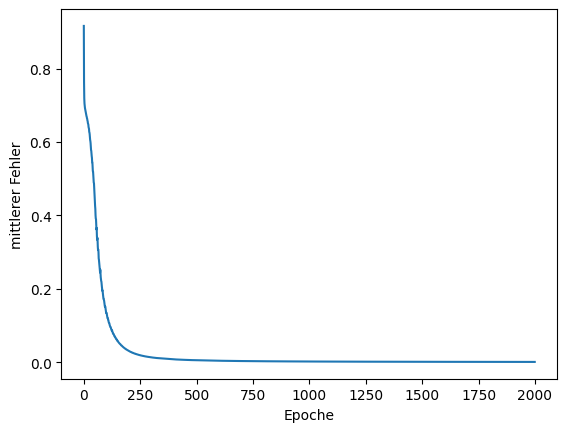

In [15]:
import matplotlib.pyplot as plt

plt.plot(verlauf)
plt.xlabel('Epoche')
plt.ylabel('mittlerer Fehler')
plt.show()

Das Netz mit 8 versteckten Neuronen hat XOR gelernt. Mit weniger Neuronen klappt das nicht immer. Wir trainieren
mit 20 verschiedenen Startwerten und zählen, wie oft der Fehler am Ende unter 0.1 liegt. Außerdem zählen wir
**tote** Neuronen: versteckte Neuronen, deren Summe $z_j$ bei allen vier Inputs $\le 0$ ist.

In [16]:
def tote_neuronen(X, W, b):
    return sum(all(vorwaerts(x, W, b, [[0] * len(W)], [0])[0][j] <= 0 for x in X) for j in range(len(W)))

for anzahl_h in [3, 8]:
    erfolge = 0
    tote = []
    for seed in range(20):
        W, b, V, c, verlauf = trainieren(X, Y, anzahl_h, 2000, 0.5, seed)
        if verlauf[-1] < 0.1:
            erfolge += 1
        else:
            tote.append(tote_neuronen(X, W, b))
    print(anzahl_h, 'versteckte Neuronen:', erfolge, 'von 20 erfolgreich, tote Neuronen bei den anderen:', tote)

3 versteckte Neuronen: 9 von 20 erfolgreich, tote Neuronen bei den anderen: [2, 1, 1, 2, 1, 3, 1, 1, 2, 3, 1]


8 versteckte Neuronen: 20 von 20 erfolgreich, tote Neuronen bei den anderen: []


Mit 3 versteckten Neuronen lernt das Netz XOR nur in 9 von 20 Fällen. Bei allen 11 Fehlschlägen ist mindestens ein
Neuron tot. Für ein totes Neuron ist $ReLU'(z_j) = 0$ bei allen Inputs, also auch $\delta_j = 0$: Seine Gewichte
bekommen nie mehr eine Ableitung ungleich 0 und ändern sich nicht mehr. Bleiben zu wenige lebende Neuronen übrig,
reicht es nicht für XOR. Mit 8 Neuronen bleiben immer genug übrig. Große Netze haben deshalb meist mehr Neuronen,
als für die Aufgabe eigentlich nötig wären.

### Automatisch rückwärts: die Klasse `Wert`

Unser Rechenschema funktioniert nur für genau diesen Netzaufbau: eine versteckte Schicht mit ReLU, Ausgaben mit
Sigmoid. Für jeden anderen Aufbau müssten wir die Formeln neu herleiten. Bibliotheken wie PyTorch machen das
automatisch: Sie merken sich bei jeder Rechnung den Rechengraphen und gehen ihn anschließend rückwärts durch. Das
heißt **automatisches Differenzieren**.

Das geht auch mit einer kleinen eigenen Klasse (nach der Idee von *micrograd* von Andrej Karpathy). Ein `Wert`
speichert

- seinen Zahlenwert `wert`,
- die Ableitung `grad` des Endergebnisses nach diesem Wert, am Anfang 0,
- die Werte `kinder`, aus denen er berechnet wurde,
- eine Funktion `_zurueck`, die seine Ableitung mit den lokalen Ableitungen an die Kinder weitergibt.

In [17]:
class Wert:
    def __init__(self, wert, kinder=()):
        self.wert = wert
        self.grad = 0
        self.kinder = kinder
        self._zurueck = lambda: None

    def __repr__(self):
        return f'Wert({self.wert:.4f}, grad={self.grad:.4f})'

    def __add__(self, other):
        other = other if isinstance(other, Wert) else Wert(other)
        erg = Wert(self.wert + other.wert, (self, other))
        def zurueck():
            self.grad += erg.grad
            other.grad += erg.grad
        erg._zurueck = zurueck
        return erg

    def __mul__(self, other):
        other = other if isinstance(other, Wert) else Wert(other)
        erg = Wert(self.wert * other.wert, (self, other))
        def zurueck():
            self.grad += other.wert * erg.grad
            other.grad += self.wert * erg.grad
        erg._zurueck = zurueck
        return erg

    def __radd__(self, other):
        return self + other

    def __rmul__(self, other):
        return self * other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __rsub__(self, other):
        return other + (-self)

    def sigmoid(self):
        s = 1 / (1 + math.exp(-self.wert))
        erg = Wert(s, (self,))
        def zurueck():
            self.grad += s * (1 - s) * erg.grad
        erg._zurueck = zurueck
        return erg

    def relu(self):
        erg = Wert(max(0, self.wert), (self,))
        def zurueck():
            self.grad += (1 if self.wert > 0 else 0) * erg.grad
        erg._zurueck = zurueck
        return erg

    def log(self):
        erg = Wert(math.log(self.wert), (self,))
        def zurueck():
            self.grad += 1 / self.wert * erg.grad
        erg._zurueck = zurueck
        return erg

    def rueckwaerts(self):
        reihenfolge = []
        besucht = set()
        def besuche(v):
            if v not in besucht:
                besucht.add(v)
                for kind in v.kinder:
                    besuche(kind)
                reihenfolge.append(v)
        besuche(self)
        self.grad = 1
        for v in reversed(reihenfolge):
            v._zurueck()

Jede Rechenoperation erzeugt einen neuen `Wert` und hinterlegt in `_zurueck` ihre lokale Ableitung: beim Plus 1,
beim Mal den anderen Faktor, bei Sigmoid $s(1 - s)$, bei ReLU 1 oder 0, beim Logarithmus $\frac{1}{x}$.

Wichtig ist das `+=`: Wird ein Wert an mehreren Stellen benutzt, kommen Beiträge auf mehreren Wegen zurück und
werden addiert.

`rueckwaerts` muss die Knoten in der richtigen Reihenfolge abarbeiten: Ein Knoten darf seine Ableitung erst
weitergeben, wenn alle Beiträge von den Knoten angekommen sind, die ihn benutzen. Dazu sammelt eine **Tiefensuche**
die Knoten so, dass jeder Knoten nach seinen Kindern kommt (topologische Sortierung). Rückwärts durchlaufen kommt dann
jeder Knoten vor seinen Kindern dran.

Die beiden Beispiele vom Anfang:

In [18]:
x, y, z = Wert(1), Wert(2), Wert(-2)
f = (x + y) * z
f.rueckwaerts()
print(f, x, y, z)

x, y = Wert(3), Wert(-1)
f = (x + y) * x
f.rueckwaerts()
print(f, x, y)

Wert(-6.0000, grad=1.0000) Wert(1.0000, grad=-2.0000) Wert(2.0000, grad=-2.0000) Wert(-2.0000, grad=3.0000)
Wert(6.0000, grad=1.0000) Wert(3.0000, grad=5.0000) Wert(-1.0000, grad=3.0000)


Und das Netz aus Stufe 4. Die Rechnung schreiben wir einfach hin wie mit Zahlen, die Ableitungen kommen von allein
und stimmen mit unserer Tabelle überein:

In [19]:
x1, x2, y = 1, 1, 1
w11, w12, b1 = Wert(1), Wert(0.5), Wert(-0.5)
w21, w22, b2 = Wert(0.5), Wert(0.5), Wert(1)
v1, v2, c = Wert(2), Wert(-1), Wert(0)

h1 = (w11 * x1 + w12 * x2 + b1).relu()
h2 = (w21 * x1 + w22 * x2 + b2).relu()
yh = (v1 * h1 + v2 * h2 + c).sigmoid()
L = -(y * yh.log() + (1 - y) * (1 - yh).log())
L.rueckwaerts()

print(yh, L)
for name, p in [('w11', w11), ('w12', w12), ('b1', b1), ('w21', w21), ('w22', w22), ('b2', b2),
                ('v1', v1), ('v2', v2), ('c', c)]:
    print(name, round(p.grad, 4))

Wert(0.5000, grad=-2.0000) Wert(0.6931, grad=1.0000)
w11 -1.0
w12 -1.0
b1 -1.0
w21 0.5
w22 0.5
b2 0.5
v1 -0.5
v2 -1.0
c -0.5


Genau so arbeitet PyTorch, nur mit Tensoren statt einzelnen Zahlen und viel schneller. In neuronaleNetze4 sehen wir,
dass PyTorch für dieses Netz dieselben Zahlen liefert.

### Probleme beim Lernen

**Tote Neuronen:** Ist $z_j \le 0$ für alle Trainingsbeispiele, dann ist $\delta_j = 0$, und die Gewichte des Neurons
ändern sich nie mehr. Das passiert leicht nach einem zu großen Schritt (siehe Aufgaben).

**Zu große Lernrate:** Die Ableitung gilt nur in der Nähe des aktuellen Werts. Ein zu großer Schritt kann über das
Minimum hinausschießen, der Fehler wird dann größer statt kleiner.

**Verschwindende Ableitungen:** Die Ableitung der Sigmoidfunktion $\sigma(z)(1 - \sigma(z))$ ist höchstens 0.25
(bei $z = 0$). Hätte jede Schicht eines tiefen Netzes Sigmoid, würde $\delta$ auf dem Weg zurück in jeder Schicht mit
höchstens 0.25 multipliziert:

In [20]:
for schichten in [1, 5, 10, 20]:
    print(schichten, 0.25 ** schichten)

1 0.25
5 0.0009765625
10 9.5367431640625e-07
20 9.094947017729282e-13


Nach 10 Schichten ist das Fehlersignal fast verschwunden, die vorderen Schichten lernen kaum noch. Die Ableitung der
ReLU ist dagegen 1 für aktive Neuronen. Deshalb benutzt man heute in den versteckten Schichten ReLU oder ähnliche
Funktionen und Sigmoid nur noch in der Ausgabe.

### Zusammenfassung

- Der Fehler hängt über einen Rechengraphen von allen Parametern ab. Rückwärts multipliziert man die ankommende
  Ableitung mit der lokalen Ableitung jedes Knotens (Kettenregel). Führen mehrere Wege zu einem Wert, werden die
  Beiträge addiert.
- Mit Sigmoid und Binary Cross-Entropy ist das Fehlersignal des Ausgabeneurons einfach $\delta_o = \hat{y} - y$.
- Das Fehlersignal eines versteckten Neurons ist die Summe der Fehlersignale dahinter, jeweils mal Gewicht, mal
  Ableitung der eigenen Aktivierung.
- Die Ableitung nach einem Gewicht ist $\delta$ des Zielneurons mal dem Wert, der über das Gewicht hereinkommt.
- Ein Durchgang vorwärts und einer rückwärts liefern alle Ableitungen, dann folgt das Update
  $p_{neu} = p - lr \cdot \frac{\partial L}{\partial p}$.